# Customer Support Ticket Analytics
### An End-to-End Python Case Study | Data Quality · Service Operations · Customer Experience

**Portfolio Project 02** · **Tools:** Python, Pandas, NumPy, Matplotlib · **Dataset:** `support-tickets.csv` (synthetic support tickets)

**Business objective:** Understand support demand, response speed, resolution speed, queue workload, ticket reopening, and customer satisfaction—without mistaking missing records for valid zero values.

**What this notebook delivers**
1. Reproducible import and source-data audit
2. Date parsing, validation, and defensible derived metrics
3. Clearly defined KPIs with explicit denominators
4. Exploratory analysis of time, queue, priority, and channel
5. Visualizations, executive findings, limitations, and a cleaned export

> **Interpretation note:** This dataset is synthetic and lacks explicit SLA targets, current ticket status, survey methodology, and a verified export timestamp. We will not invent SLA compliance or label every missing resolution timestamp as a currently open ticket.

## 1. Environment Setup and CSV Import

We load the libraries needed for tabular analysis and plotting. The CSV is searched for in a few **relative** locations, making the notebook convenient to run from its project folder. The first existing candidate is selected. Paths are relative to the **current working directory**, which may not always be the notebook's directory.

**How to run:** This portfolio stores `support-tickets.csv` in `data/raw/`. Open this notebook from `notebooks/` or run it from the project root, then choose **Run All** in Jupyter or VS Code. The processed output is saved to `data/processed/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

SOURCE_CANDIDATES = [
    Path("data/raw/support-tickets.csv"),
    Path("../data/raw/support-tickets.csv"),
    Path("support-tickets.csv"),
    Path("../support-tickets.csv"),
    Path("data/support-tickets.csv"),
]

available_files = [path for path in SOURCE_CANDIDATES if path.is_file()]
if not available_files:
    raise FileNotFoundError(
        "Could not locate support-tickets.csv. Run from the project root "
        "or its notebooks folder, or update SOURCE_CANDIDATES."
    )

source_path = available_files[0]
raw_df = pd.read_csv(source_path, encoding="utf-8-sig", dtype={"ticket_id": "string"})

print(f"Data source: {source_path}")
print(f"Imported: {len(raw_df):,} rows × {raw_df.shape[1]} columns")
display(raw_df.head(5))

Data source: support-tickets.csv
Imported: 4,000 rows × 10 columns


,ticket_id,opened_at,channel,queue,priority,subject,first_response_min,resolved_at,reopened,csat
0,TK62871,2023-01-01 02:15:00,in-app,onboarding,high,Error when log in after password reset,63.00,2023-01-01 07:46:35,True,NaN
1,TK60343,2023-01-01 05:41:00,email,technical,normal,Question about two-factor authentication,7.00,2023-01-01 09:07:58,False,NaN
2,TK62950,2023-01-01 06:05:00,in-app,billing,urgent,Unable to connecting the Snowflake sync,44.00,2023-01-01 08:14:24,False,NaN
3,TK61014,2023-01-01 06:32:00,chat,integrations,normal,Cannot connecting the Snowflake sync,98.00,NaN,False,NaN
4,TK61679,2023-01-01 08:06:00,chat,onboarding,high,How do I a duplicate charge,14.00,2023-01-01 09:27:09,False,5.00


### Understanding the import code

- **`Path(...).is_file()`** checks whether a candidate CSV actually exists.
- **List comprehension** builds a list of files that exist; `available_files[0]` selects the first one.
- **`pd.read_csv()`** loads the selected CSV into the `raw_df` DataFrame.
- **`dtype={"ticket_id": "string"}`** treats ticket identifiers as labels, not numeric quantities.
- **`head(5)`** previews five rows; it is not a cleaning operation.

We preserve `raw_df` so we can always compare cleaned data with the original import.

## 2. Understand the Data Dictionary and Types

Each row represents **one ticket**, not one customer or one message. The file contains no separate customer identifier, so unique-customer counts cannot be calculated.

| Source column | Business meaning | Notes |
|---|---|---|
| `ticket_id` | Unique ticket identifier | Must be unique and non-missing |
| `opened_at` | Ticket-opening timestamp | Date/time text at import |
| `channel` | Contact channel | Categorical: e.g., email or chat |
| `queue` | Team or routing queue | Operational grouping |
| `priority` | Assigned priority | Categorical, not an SLA target |
| `subject` | Short ticket description | Text; may contain inconsistent wording |
| `first_response_min` | Recorded first-response minutes | Missing ≠ 0 minutes |
| `resolved_at` | Recorded resolution timestamp | Missing ≠ proof of current open status |
| `reopened` | Reopening indicator | Boolean |
| `csat` | Customer satisfaction rating | Available only for rated tickets |

In [2]:
print("DATAFRAME INFORMATION")
raw_df.info()

schema_audit = pd.DataFrame({
    "Data type": raw_df.dtypes.astype(str),
    "Present": raw_df.notna().sum(),
    "Missing": raw_df.isna().sum(),
    "Missing %": 100 * raw_df.isna().mean(),
    "Distinct values": raw_df.nunique(dropna=True),
})
display(schema_audit.round(2))

DATAFRAME INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ticket_id           4000 non-null   string 
 1   opened_at           4000 non-null   object 
 2   channel             4000 non-null   object 
 3   queue               4000 non-null   object 
 4   priority            4000 non-null   object 
 5   subject             4000 non-null   object 
 6   first_response_min  3851 non-null   float64
 7   resolved_at         3775 non-null   object 
 8   reopened            4000 non-null   bool   
 9   csat                1226 non-null   float64
dtypes: bool(1), float64(2), object(6), string(1)
memory usage: 285.3+ KB


,Data type,Present,Missing,Missing %,Distinct values
ticket_id,string,4000,0,0.00,4000
opened_at,object,4000,0,0.00,3990
channel,object,4000,0,0.00,4
queue,object,4000,0,0.00,5
priority,object,4000,0,0.00,4
subject,object,4000,0,0.00,84
first_response_min,float64,3851,149,3.72,622
resolved_at,object,3775,225,5.62,3775
reopened,bool,4000,0,0.00,2
csat,float64,1226,2774,69.35,5


### What the audit methods mean

- **`.info()`** reports column types and non-null counts.
- **`.notna().sum()`** counts observed values.
- **`.isna().sum()`** counts missing values.
- **`.nunique(dropna=True)`** counts different non-missing values.
- **`.mean()`** on a Boolean missing-value mask gives the fraction missing.

**Crucial:** Missing `csat` is not a rating of zero. Likewise, missing `resolved_at` is not a zero-hour resolution.

## 3. Validate the Raw Ticket-Level Dataset

A dashboard can look credible even if records are missing. We therefore verify the source structure, blank IDs, duplicate ticket IDs, exact duplicate rows, and categorical labels **before cleaning**.

In [3]:
REQUIRED_COLUMNS = {
    "ticket_id", "opened_at", "channel", "queue", "priority", "subject",
    "first_response_min", "resolved_at", "reopened", "csat",
}

missing_columns = sorted(REQUIRED_COLUMNS - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

blank_ticket_ids = raw_df["ticket_id"].isna() | raw_df["ticket_id"].str.strip().eq("")

raw_audit = pd.DataFrame({
    "Check": [
        "Rows", "Columns", "Unique ticket IDs", "Duplicated ticket IDs",
        "Fully duplicated rows", "Blank/missing ticket IDs",
    ],
    "Result": [
        len(raw_df), raw_df.shape[1], raw_df["ticket_id"].nunique(),
        int(raw_df["ticket_id"].duplicated().sum()),
        int(raw_df.duplicated().sum()), int(blank_ticket_ids.sum()),
    ],
})
display(raw_audit)

assert not blank_ticket_ids.any(), "Ticket IDs must not be blank."
assert raw_df["ticket_id"].is_unique, "Duplicate ticket IDs detected."
assert len(raw_df) == 4_000, "Expected 4,000 rows in this source dataset."
assert raw_df.shape[1] == 10, "Unexpected source column count."

for col in ["channel", "queue", "priority"]:
    print(f"{col}: {sorted(raw_df[col].dropna().astype(str).unique().tolist())}")

,Check,Result
0,Rows,4000
1,Columns,10
2,Unique ticket IDs,4000
3,Duplicated ticket IDs,0
4,Fully duplicated rows,0
5,Blank/missing ticket IDs,0


channel: ['chat', 'email', 'in-app', 'phone']
queue: ['account', 'billing', 'integrations', 'onboarding', 'technical']
priority: ['high', 'low', 'normal', 'urgent']


## 4. Create a Clean Working DataFrame

We work on a **copy** so that `raw_df` stays available for cross-checking. Dates are parsed with an explicit format. `errors="coerce"` converts unparseable timestamps to missing datetime values (`NaT`), so we must *count* conversion failures instead of hiding them.

We normalize spaces and capitalization in categorical columns without inventing new ticket classes. Existing missing values are retained.

In [4]:
clean_df = raw_df.copy()

for col in ["channel", "queue", "priority"]:
    clean_df[col] = clean_df[col].astype("string").str.strip().str.lower()

clean_df["subject"] = clean_df["subject"].astype("string").str.strip()

for col in ["first_response_min", "csat"]:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

DATE_FORMAT = "%Y-%m-%d %H:%M:%S"
for col in ["opened_at", "resolved_at"]:
    clean_df[col] = pd.to_datetime(
        clean_df[col], format=DATE_FORMAT, errors="coerce"
    )

conversion_failures = {
    col: int((raw_df[col].notna() & clean_df[col].isna()).sum())
    for col in ["opened_at", "resolved_at", "first_response_min", "csat"]
}
print("Unexpected conversion failures:", conversion_failures)
assert all(count == 0 for count in conversion_failures.values())

assert pd.api.types.is_bool_dtype(clean_df["reopened"]), (
    "Expected reopened to be a Boolean column. Inspect its source values."
)

print("Clean DataFrame:", clean_df.shape)
display(clean_df.head(3))

Unexpected conversion failures: {'opened_at': 0, 'resolved_at': 0, 'first_response_min': 0, 'csat': 0}
Clean DataFrame: (4000, 10)


,ticket_id,opened_at,channel,queue,priority,subject,first_response_min,resolved_at,reopened,csat
0,TK62871,2023-01-01 02:15:00,in-app,onboarding,high,Error when log in after password reset,63.00,2023-01-01 07:46:35,True,NaN
1,TK60343,2023-01-01 05:41:00,email,technical,normal,Question about two-factor authentication,7.00,2023-01-01 09:07:58,False,NaN
2,TK62950,2023-01-01 06:05:00,in-app,billing,urgent,Unable to connecting the Snowflake sync,44.00,2023-01-01 08:14:24,False,NaN


## 5. Date-Based Features and Resolution Durations

The **resolution duration** is the elapsed time between `opened_at` and `resolved_at`, measured in **hours**. A timestamp missing from `resolved_at` produces a missing duration, not zero.

We also extract reporting month, year, weekday, and hour from the ticket-opening date. The dataset has no stated timezone; we **do not assign one**.

In [5]:
clean_df["opened_date"] = clean_df["opened_at"].dt.date
clean_df["opened_year"] = clean_df["opened_at"].dt.year
clean_df["opened_month"] = clean_df["opened_at"].dt.to_period("M").astype("string")
clean_df["opened_weekday"] = clean_df["opened_at"].dt.day_name()
clean_df["opened_hour"] = clean_df["opened_at"].dt.hour

clean_df["resolution_hours"] = (
    clean_df["resolved_at"] - clean_df["opened_at"]
).dt.total_seconds() / 3600

clean_df["resolution_recorded"] = clean_df["resolved_at"].notna()
clean_df["resolution_hours_valid"] = clean_df["resolution_hours"].mask(
    clean_df["resolution_hours"] < 0
)

print("Opened dates:", clean_df["opened_at"].min(), "to", clean_df["opened_at"].max())
print("Missing resolution timestamps:", clean_df["resolved_at"].isna().sum())
print("Negative resolution durations:", (clean_df["resolution_hours"] < 0).sum())
display(clean_df[[
    "ticket_id", "opened_at", "resolved_at", "resolution_hours"
]].head(6))

Opened dates: 2023-01-01 02:15:00 to 2024-02-04 17:27:00
Missing resolution timestamps: 225
Negative resolution durations: 0


,ticket_id,opened_at,resolved_at,resolution_hours
0,TK62871,2023-01-01 02:15:00,2023-01-01 07:46:35,5.53
1,TK60343,2023-01-01 05:41:00,2023-01-01 09:07:58,3.45
2,TK62950,2023-01-01 06:05:00,2023-01-01 08:14:24,2.16
3,TK61014,2023-01-01 06:32:00,NaT,NaN
4,TK61679,2023-01-01 08:06:00,2023-01-01 09:27:09,1.35
5,TK62374,2023-01-01 08:28:00,2023-01-02 02:19:53,17.86


## 6. Important Chronology Quality Check: First Response vs. Resolution

A recorded first response should generally occur **before or at** the recorded resolution timestamp. To test this, compare `first_response_min` against the elapsed opening-to-resolution minutes *only for tickets with both values*.

If the recorded response comes **after** resolution, it is a chronology inconsistency. **Do not silently delete the ticket.** We flag the inconsistency and create a separate validated response-time column for KPI use.

For tickets without a resolution timestamp, this comparison is impossible; a non-negative recorded response remains eligible for the response-time KPI.

In [6]:
clean_df["negative_response_flag"] = clean_df["first_response_min"] < 0
clean_df["response_after_resolution_flag"] = (
    clean_df["first_response_min"].notna()
    & clean_df["resolution_hours_valid"].notna()
    & (
        clean_df["first_response_min"]
        > clean_df["resolution_hours_valid"] * 60
    )
)

clean_df["first_response_valid_min"] = clean_df["first_response_min"].mask(
    clean_df["negative_response_flag"]
    | clean_df["response_after_resolution_flag"]
)

clean_df["csat_invalid_flag"] = (
    clean_df["csat"].notna()
    & (~clean_df["csat"].isin([1, 2, 3, 4, 5]))
)
clean_df["csat_valid"] = clean_df["csat"].mask(clean_df["csat_invalid_flag"])

quality_checks = pd.DataFrame({
    "Quality check": [
        "Negative resolution durations",
        "Negative first-response minutes",
        "First response recorded after resolution",
        "Invalid non-missing CSAT ratings",
        "First-response values missing in source",
        "Resolution timestamps missing in source",
        "CSAT ratings missing in source",
    ],
    "Affected tickets": [
        int((clean_df["resolution_hours"] < 0).sum()),
        int(clean_df["negative_response_flag"].sum()),
        int(clean_df["response_after_resolution_flag"].sum()),
        int(clean_df["csat_invalid_flag"].sum()),
        int(raw_df["first_response_min"].isna().sum()),
        int(raw_df["resolved_at"].isna().sum()),
        int(raw_df["csat"].isna().sum()),
    ],
})
display(quality_checks)
print("Response observations before chronology screening:", clean_df["first_response_min"].count())
print("Validated response observations:", clean_df["first_response_valid_min"].count())

,Quality check,Affected tickets
0,Negative resolution durations,0
1,Negative first-response minutes,0
2,First response recorded after resolution,143
3,Invalid non-missing CSAT ratings,0
4,First-response values missing in source,149
5,Resolution timestamps missing in source,225
6,CSAT ratings missing in source,2774


Response observations before chronology screening: 3851
Validated response observations: 3708


**How to interpret the flags**

- For this file, **143** tickets have first-response minutes exceeding their recorded resolution durations.
- These 143 tickets **remain in the dataset and ticket-count KPIs**.
- Their questionable first-response values are excluded **only** from the validated first-response KPI and relevant comparisons. We do **not** change their recorded resolution times.
- We cannot determine from this dataset alone whether the inconsistency stems from logging behavior, a data-generation problem, or something else.

This is a real quality-control step that makes the project stronger than simply running `.mean()` on every numeric column.

## 7. Data Quality Assertions and Reference Totals

Assertions act as safety checks: if the assumptions no longer hold, notebook execution stops rather than silently displaying misleading metrics. These checks describe **this exact uploaded CSV**, not universal business rules.

In [7]:
assert len(clean_df) == len(raw_df) == 4_000
assert clean_df["ticket_id"].nunique() == 4_000
assert clean_df["opened_at"].notna().all()
assert (clean_df["resolution_hours"].dropna() >= 0).all()
assert clean_df["resolution_recorded"].sum() == 3_775
assert clean_df["first_response_min"].isna().sum() == 149
assert clean_df["csat_valid"].isna().sum() == 2_774
assert clean_df["response_after_resolution_flag"].sum() == 143
assert clean_df["first_response_valid_min"].count() == 3_708
assert clean_df["csat_invalid_flag"].sum() == 0

print("All dataset-specific integrity checks passed.")

All dataset-specific integrity checks passed.


## 8. Define Executive KPIs (with Clear Denominators)

Definitions matter more than attractive dashboard cards. This dataset supports the following descriptive KPIs:

| KPI | Calculation / population |
|---|---|
| Ticket volume | Count of distinct `ticket_id` |
| Resolution timestamp coverage | Tickets with `resolved_at` ÷ all tickets |
| Validated median first response | Median of recorded, non-negative, chronology-consistent first-response minutes |
| Median resolution duration | Median resolution hours among tickets with valid timestamps |
| Reopening rate | Tickets marked `reopened=True` ÷ all tickets |
| Average CSAT | Mean of **recorded valid ratings only** (1–5 scale) |
| CSAT coverage | Tickets with recorded valid CSAT ÷ all tickets |

**Not available:** SLA compliance (no documented SLA threshold), true current backlog (no verified export timestamp / live status), customer-level retention (no customer identifier).

In [8]:
total_tickets = clean_df["ticket_id"].nunique()
resolution_count = int(clean_df["resolution_recorded"].sum())
response_valid_count = int(clean_df["first_response_valid_min"].count())
rated_count = int(clean_df["csat_valid"].count())

kpis = pd.DataFrame({
    "Metric": [
        "Distinct tickets",
        "Resolution timestamps recorded",
        "Resolution timestamp coverage (%)",
        "Validated response observations",
        "Validated median first response (min)",
        "Median resolution duration (hours)",
        "Reopened tickets",
        "Reopening rate (%)",
        "Rated tickets (CSAT)",
        "CSAT coverage (%)",
        "Average CSAT (1–5; rated tickets only)",
        "Positive CSAT share (% of rated; scores 4–5)",
    ],
    "Value": [
        total_tickets,
        resolution_count,
        100 * resolution_count / total_tickets,
        response_valid_count,
        clean_df["first_response_valid_min"].median(),
        clean_df["resolution_hours_valid"].median(),
        int(clean_df["reopened"].sum()),
        100 * clean_df["reopened"].mean(),
        rated_count,
        100 * rated_count / total_tickets,
        clean_df["csat_valid"].mean(),
        100 * clean_df["csat_valid"].ge(4).sum() / rated_count,
    ],
})
display(kpis.round(2))

,Metric,Value
0,Distinct tickets,"4,000.00"
1,Resolution timestamps recorded,"3,775.00"
2,Resolution timestamp coverage (%),94.38
3,Validated response observations,"3,708.00"
4,Validated median first response (min),80.00
5,Median resolution duration (hours),24.63
6,Reopened tickets,285.00
7,Reopening rate (%),7.12
8,Rated tickets (CSAT),"1,226.00"
9,CSAT coverage (%),30.65


### Reading these KPIs responsibly

**Median vs. mean:** A median is less sensitive than a mean to a few unusually long tickets. We use the median as the headline speed metric but also inspect the full distribution.

**Coverage is not a performance target:** A ticket without a resolution timestamp is *not automatically* an SLA breach or currently open ticket.

**CSAT selection:** Only **1,226 of 4,000** tickets have ratings. The measured average must never be presented as the opinion of all customers.

## 9. Analyze First-Response and Resolution Distributions

Percentiles reveal slow-tail behavior. The 90th percentile means that **90% of the measured sample** lies at or below the corresponding value. Percentiles can be more operationally helpful than a simple mean.

In [9]:
response_distribution = clean_df["first_response_valid_min"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)
resolution_distribution = clean_df["resolution_hours_valid"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
)

display(pd.DataFrame({
    "First response (min; validated)": response_distribution,
    "Resolution duration (hours)": resolution_distribution,
}).round(2))

,First response (min; validated),Resolution duration (hours)
count,"3,708.00","3,775.00"
mean,139.38,58.92
std,201.39,108.78
min,1.00,0.04
25%,36.00,9.23
50%,80.00,24.63
75%,168.00,62.19
90%,310.30,140.36
95%,455.65,219.03
max,"4,444.00","2,130.48"


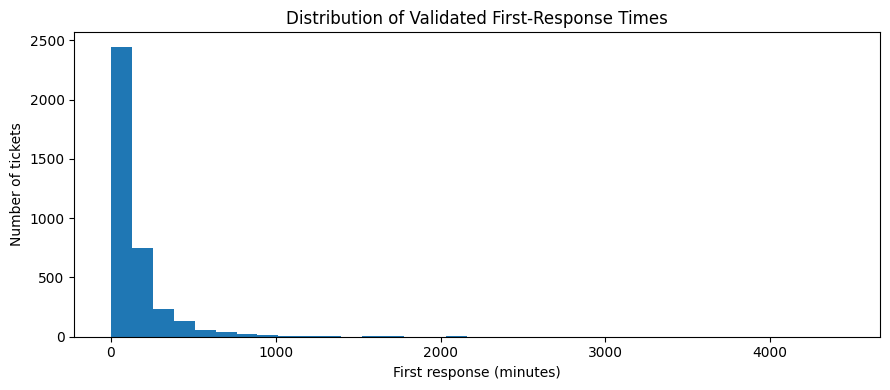

In [10]:
# One visual per figure for a readable notebook.
plt.figure(figsize=(9, 4))
plt.hist(clean_df["first_response_valid_min"].dropna(), bins=35)
plt.title("Distribution of Validated First-Response Times")
plt.xlabel("First response (minutes)")
plt.ylabel("Number of tickets")
plt.tight_layout()
plt.show()

The histogram shows the full range, including slow-response outliers. If the plot looks compressed on the left, that is a clue to examine upper percentiles rather than deleting extremes without evidence.

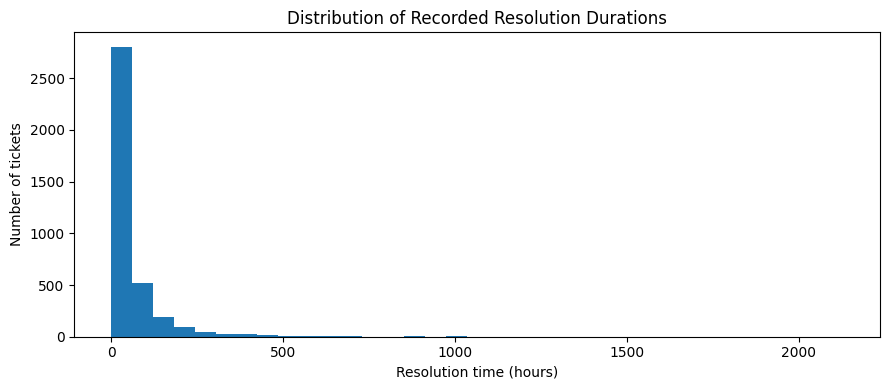

In [11]:
plt.figure(figsize=(9, 4))
plt.hist(clean_df["resolution_hours_valid"].dropna(), bins=35)
plt.title("Distribution of Recorded Resolution Durations")
plt.xlabel("Resolution time (hours)")
plt.ylabel("Number of tickets")
plt.tight_layout()
plt.show()

## 10. Ticket Volume Over Time

We aggregate tickets by their **opening month**, not by resolution month, to measure incoming workload. **February 2024 is incomplete** in this file; comparing its raw count with a full month would be misleading.

,opened_month,tickets
0,2023-01,320
1,2023-02,290
2,2023-03,282
3,2023-04,303
4,2023-05,310
5,2023-06,297
6,2023-07,303
7,2023-08,333
8,2023-09,255
9,2023-10,318


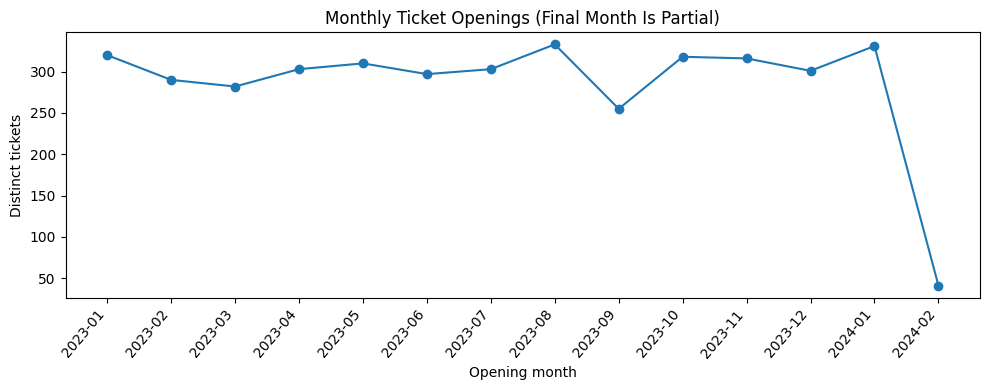

In [12]:
monthly_volume = (
    clean_df.groupby("opened_month", dropna=False)["ticket_id"]
    .nunique()
    .rename("tickets")
    .reset_index()
    .sort_values("opened_month")
)

assert monthly_volume["tickets"].sum() == total_tickets
display(monthly_volume)

plt.figure(figsize=(10, 4))
plt.plot(monthly_volume["opened_month"], monthly_volume["tickets"], marker="o")
plt.title("Monthly Ticket Openings (Final Month Is Partial)")
plt.xlabel("Opening month")
plt.ylabel("Distinct tickets")
plt.xticks(rotation=50, ha="right")
plt.tight_layout()
plt.show()

**Time-window caution:** This extract spans January 2023 through early February 2024. A downturn in the last displayed month may reflect **partial-month coverage**, not lower customer demand.

## 11. Reusable Support-Performance Summary Function

Rather than repeating separate `groupby()` calculations for each business dimension, we create **one consistent function**.

- **`groupby(dimension)`** partitions the tickets by channel, queue, or priority.
- **`.agg()`** calculates ticket counts, response/resolution medians, reopening counts, and CSAT observations.
- **Rates are calculated after aggregation** using each group's actual ticket count as denominator.
- A group's `Average CSAT` uses rated tickets only; we also show its sample size.

In [13]:
def support_performance_by(dimension: str) -> pd.DataFrame:
    """Return consistent descriptive metrics grouped by one ticket attribute."""
    result = (
        clean_df.groupby(dimension, dropna=False)
        .agg(
            tickets=("ticket_id", "nunique"),
            recorded_resolutions=("resolution_recorded", "sum"),
            validated_responses=("first_response_valid_min", "count"),
            median_first_response_min=("first_response_valid_min", "median"),
            median_resolution_hours=("resolution_hours_valid", "median"),
            reopened_tickets=("reopened", "sum"),
            rated_tickets=("csat_valid", "count"),
            average_csat=("csat_valid", "mean"),
        )
        .reset_index()
    )
    result["resolution_timestamp_pct"] = 100 * result["recorded_resolutions"] / result["tickets"]
    result["reopen_rate_pct"] = 100 * result["reopened_tickets"] / result["tickets"]
    result["csat_coverage_pct"] = 100 * result["rated_tickets"] / result["tickets"]
    assert int(result["tickets"].sum()) == total_tickets
    return result.sort_values("tickets", ascending=False).reset_index(drop=True)

print("Support summary function ready.")

Support summary function ready.


## 12. Queue Analysis: Workload and Resolution Speed

Support queues may have very different ticket mixes. First identify **which queue has the highest volume**, then compare **median resolution duration**. A longer duration does not by itself prove the team is underperforming; difficulty, priority, and routing could differ.

,queue,tickets,recorded_resolutions,validated_responses,median_first_response_min,median_resolution_hours,reopened_tickets,rated_tickets,average_csat,resolution_timestamp_pct,reopen_rate_pct,csat_coverage_pct
0,technical,1282,1178,1213,78.00,39.19,84,377,3.85,91.89,6.55,29.41
1,billing,960,922,860,79.50,16.07,83,292,3.95,96.04,8.65,30.42
2,account,647,627,591,78.00,17.16,42,190,4.08,96.91,6.49,29.37
3,onboarding,586,569,550,75.00,16.12,40,204,4.01,97.10,6.83,34.81
4,integrations,525,479,494,95.00,42.67,36,163,4.24,91.24,6.86,31.05


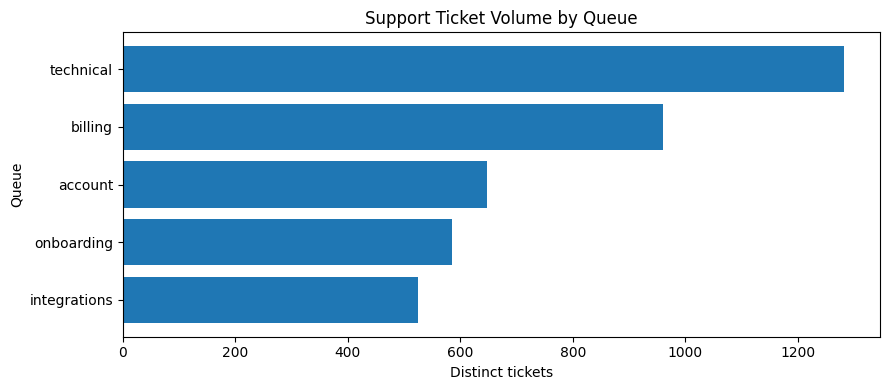

In [14]:
queue_performance = support_performance_by("queue")
display(queue_performance.round(2))

plt.figure(figsize=(9, 4))
plt.barh(queue_performance["queue"], queue_performance["tickets"])
plt.gca().invert_yaxis()
plt.title("Support Ticket Volume by Queue")
plt.xlabel("Distinct tickets")
plt.ylabel("Queue")
plt.tight_layout()
plt.show()

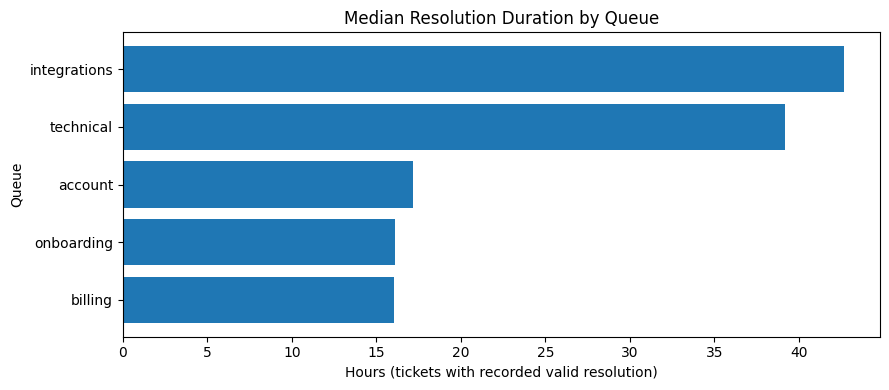

In [15]:
queue_speed = queue_performance.sort_values("median_resolution_hours", ascending=True)
plt.figure(figsize=(9, 4))
plt.barh(queue_speed["queue"], queue_speed["median_resolution_hours"])
plt.title("Median Resolution Duration by Queue")
plt.xlabel("Hours (tickets with recorded valid resolution)")
plt.ylabel("Queue")
plt.tight_layout()
plt.show()

## 13. Priority Analysis: Does Priority Align with Faster Handling?

Compare median times across priority levels. In this dataset, **urgent** tickets show faster recorded response and resolution than **low** priority tickets. This is an *association*, not proof that assigning a higher priority caused faster handling.

,priority,tickets,recorded_resolutions,validated_responses,median_first_response_min,median_resolution_hours,reopened_tickets,rated_tickets,average_csat,resolution_timestamp_pct,reopen_rate_pct,csat_coverage_pct
0,urgent,298,284,282,19.00,4.98,22,79,4.04,95.30,7.38,26.51
1,high,903,851,842,40.00,12.06,62,257,3.89,94.24,6.87,28.46
2,normal,1935,1822,1788,96.00,28.43,134,617,4.00,94.16,6.93,31.89
3,low,864,818,796,173.50,55.85,67,273,4.02,94.68,7.75,31.60


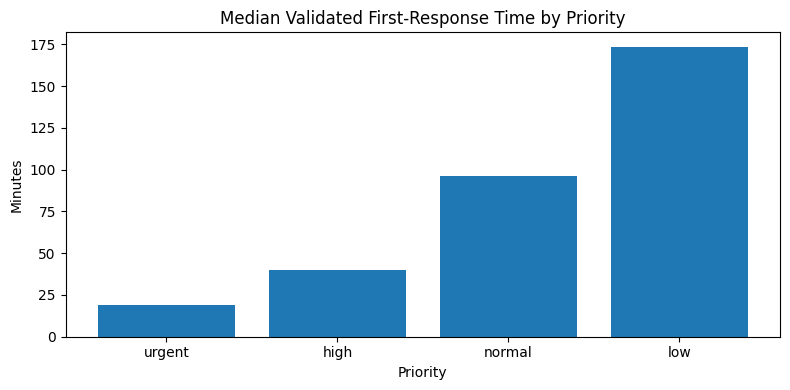

In [16]:
priority_performance = support_performance_by("priority")
priority_order = ["urgent", "high", "normal", "low"]
priority_performance["priority"] = pd.Categorical(
    priority_performance["priority"], categories=priority_order, ordered=True
)
priority_performance = priority_performance.sort_values("priority").reset_index(drop=True)
display(priority_performance.round(2))

plt.figure(figsize=(8, 4))
plt.bar(priority_performance["priority"].astype(str), priority_performance["median_first_response_min"])
plt.title("Median Validated First-Response Time by Priority")
plt.ylabel("Minutes")
plt.xlabel("Priority")
plt.tight_layout()
plt.show()

## 14. Channel Analysis: Where Do Tickets Arrive?

A large channel volume indicates demand on that channel; it does not necessarily mean the channel is inefficient. The comparison table includes service speed, CSAT coverage, and reopening for context.

,channel,tickets,recorded_resolutions,validated_responses,median_first_response_min,median_resolution_hours,reopened_tickets,rated_tickets,average_csat,resolution_timestamp_pct,reopen_rate_pct,csat_coverage_pct
0,email,1368,1298,1256,80.00,25.04,105,408,3.98,94.88,7.68,29.82
1,chat,1191,1112,1115,76.00,24.21,82,353,4.06,93.37,6.88,29.64
2,in-app,952,899,876,82.00,24.46,64,310,3.89,94.43,6.72,32.56
3,phone,489,466,461,86.00,24.03,34,155,4.03,95.30,6.95,31.70


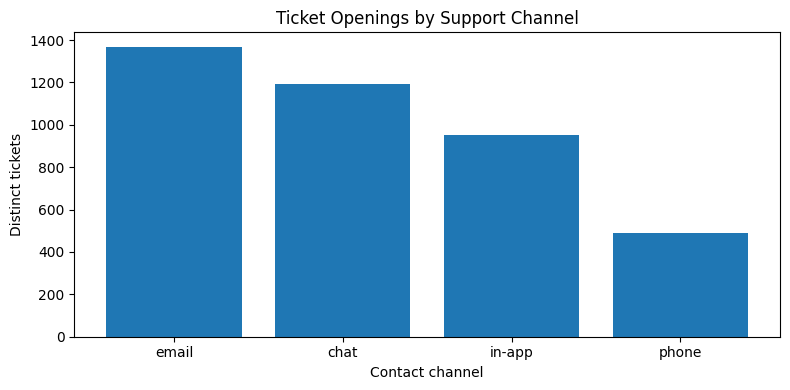

In [17]:
channel_performance = support_performance_by("channel")
display(channel_performance.round(2))

plt.figure(figsize=(8, 4))
plt.bar(channel_performance["channel"], channel_performance["tickets"])
plt.title("Ticket Openings by Support Channel")
plt.xlabel("Contact channel")
plt.ylabel("Distinct tickets")
plt.tight_layout()
plt.show()

## 15. Reopened Tickets

`reopened=True` flags tickets that were reopened at some point according to the file. It does **not** provide reopening dates, counts of reopening events, or current status.

We compare grouped summary statistics without claiming that reopening itself caused any differences.

In [18]:
reopen_summary = (
    clean_df.groupby("reopened")
    .agg(
        tickets=("ticket_id", "nunique"),
        recorded_resolutions=("resolution_recorded", "sum"),
        median_resolution_hours=("resolution_hours_valid", "median"),
        median_first_response_min=("first_response_valid_min", "median"),
        rated_tickets=("csat_valid", "count"),
        mean_csat=("csat_valid", "mean"),
    )
    .reset_index()
)
reopen_summary["ticket_share_pct"] = 100 * reopen_summary["tickets"] / total_tickets
display(reopen_summary.round(2))

,reopened,tickets,recorded_resolutions,median_resolution_hours,median_first_response_min,rated_tickets,mean_csat,ticket_share_pct
0,False,3715,3490,24.66,79.00,1131,3.98,92.88
1,True,285,285,24.36,83.00,95,4.08,7.12


## 16. Customer Satisfaction: Coverage Before Interpretation

CSAT is measured on a **1–5 scale**. Many tickets have no recorded rating, so every satisfaction comparison should disclose both **the average** and **the number/coverage of rated tickets**.

A 4+ score is used here as a **descriptive positive-rating share**, not as an official company-defined satisfaction threshold.

,rating,tickets
0,1.00,88
1,2.00,87
2,3.00,137
3,4.00,355
4,5.00,559


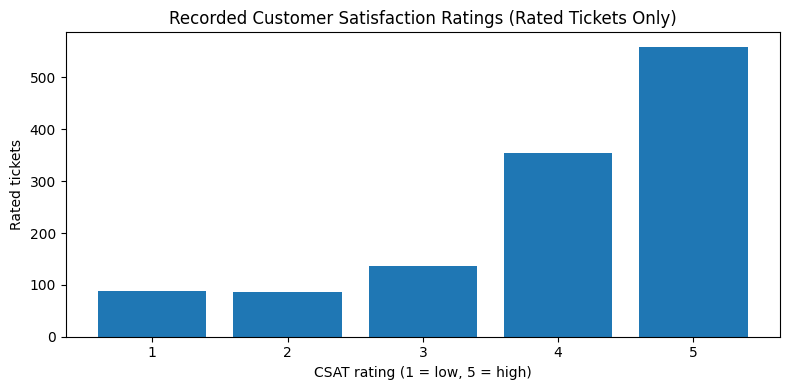

,queue,tickets,rated_tickets,csat_coverage_pct,average_csat
0,technical,1282,377,29.41,3.85
1,billing,960,292,30.42,3.95
2,account,647,190,29.37,4.08
3,onboarding,586,204,34.81,4.01
4,integrations,525,163,31.05,4.24


In [19]:
csat_distribution = (
    clean_df["csat_valid"]
    .value_counts(dropna=True)
    .sort_index()
    .rename_axis("rating")
    .reset_index(name="tickets")
)
display(csat_distribution)

plt.figure(figsize=(8, 4))
plt.bar(csat_distribution["rating"].astype(int).astype(str), csat_distribution["tickets"])
plt.title("Recorded Customer Satisfaction Ratings (Rated Tickets Only)")
plt.xlabel("CSAT rating (1 = low, 5 = high)")
plt.ylabel("Rated tickets")
plt.tight_layout()
plt.show()

csat_by_queue = queue_performance[[
    "queue", "tickets", "rated_tickets", "csat_coverage_pct", "average_csat"
]].copy()
display(csat_by_queue.round(2))

### Why CSAT coverage matters

Even a high average score can misrepresent overall customer experience if the rated tickets are not representative. The file does not explain how surveys were collected, so **avoid inferring satisfaction among unrated customers**.

## 17. Cross-Check Results Across Groupings

Here we reconcile each group's ticket counts with the full dataset. These checks help catch accidental filtering, duplicates, and missing categories in the summaries.

In [20]:
for grouping, table in [
    ("queue", queue_performance),
    ("priority", priority_performance),
    ("channel", channel_performance),
]:
    assert table["tickets"].sum() == total_tickets, f"{grouping}: lost tickets"
    assert table["recorded_resolutions"].sum() == resolution_count, f"{grouping}: resolution mismatch"
    assert table["rated_tickets"].sum() == rated_count, f"{grouping}: CSAT mismatch"
    assert table["validated_responses"].sum() == response_valid_count, f"{grouping}: response mismatch"

assert int(monthly_volume["tickets"].sum()) == total_tickets
assert int(csat_distribution["tickets"].sum()) == rated_count

print("PASS — 4,000 tickets reconcile across month, queue, priority and channel.")
print(f"PASS — {resolution_count:,} recorded resolutions reconcile across groups.")
print(f"PASS — {response_valid_count:,} validated response measurements reconcile across groups.")
print(f"PASS — {rated_count:,} recorded CSAT scores reconcile across groups.")

PASS — 4,000 tickets reconcile across month, queue, priority and channel.
PASS — 3,775 recorded resolutions reconcile across groups.
PASS — 3,708 validated response measurements reconcile across groups.
PASS — 1,226 recorded CSAT scores reconcile across groups.


## 18. Executive Findings: Evidence → Implication → Investigation

The findings below are based on **this CSV**, not external benchmarks. They are framed as operational questions instead of unverified causal claims.

### Finding 1 — Highest workload
The **technical** queue receives the most tickets (1,282 of 4,000), making it important to monitor staffing and workload distribution.

**Recommended investigation:** Compare volumes by month, priority, and ticket subject before recommending more staff.

### Finding 2 — Slow resolution in specialized queues
The **integrations** queue has a longer median recorded resolution time (approximately 42.7 hours) than account, onboarding, and billing queues. Technical also has a relatively long median (approximately 39.2 hours).

**Recommended investigation:** Review complexity, handoffs, waiting periods, and issue types in these queues.

### Finding 3 — Priority and handling speed
Urgent tickets have a median validated first-response time of approximately 19 minutes; low-priority tickets have a markedly longer median. This is consistent with prioritization, but it does not measure SLA compliance.

**Recommended investigation:** Examine whether response times meet documented service commitments once those targets are supplied.

### Finding 4 — Limited customer feedback coverage
Only 1,226 tickets have a recorded CSAT score (30.65% coverage). Average recorded CSAT is approximately 3.99/5, but this cannot be generalized to all 4,000 tickets.

**Recommended investigation:** Review survey delivery, response selection, and nonresponse bias.

### Finding 5 — Timeline data requires attention
143 tickets record first response after their resolution timestamp. These cases were flagged and excluded from the validated first-response KPI.

**Recommended investigation:** Confirm definitions and logging systems before using response-time data for individual performance evaluation.

> **Business interpretation:** These patterns show where a support manager could investigate. This observational synthetic dataset cannot establish root causes, employee performance, or policy effectiveness.

## 19. Export a Cleaned, Documented Dataset for SQL and Power BI

We export **all 4,000 original tickets**, preserving missing values and adding derived fields and quality flags. We do not remove chronology-flagged records or manufacture dates. The validated first-response column is available separately from the original recorded value.

Run this cell to create `support_tickets_cleaned.csv` in the current working directory. Later SQL/Power BI projects should use consistent column definitions and validate imported row counts.

In [ ]:
# Export alongside the portfolio's processed data when the raw source
# came from data/raw (works from either project root or notebooks/).
if source_path.parent.name == "raw" and source_path.parent.parent.name == "data":
    export_dir = source_path.parent.parent / "processed"
else:
    export_dir = Path(".")
export_dir.mkdir(parents=True, exist_ok=True)
EXPORT_PATH = export_dir / "support_tickets_cleaned.csv"
clean_df.to_csv(
    EXPORT_PATH,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d %H:%M:%S",
)

export_check = pd.read_csv(EXPORT_PATH, encoding="utf-8-sig")
assert len(export_check) == total_tickets
assert export_check["ticket_id"].nunique() == total_tickets
assert export_check["response_after_resolution_flag"].sum() == 143

print(f"Exported: {EXPORT_PATH.resolve()}")
print(f"Validated export: {len(export_check):,} rows × {export_check.shape[1]} columns")

## 20. Project Summary, Limitations, and Next Steps

### What this notebook demonstrates
- **Python/Pandas:** CSV import, DataFrame inspection, feature engineering, groupby analysis, and reusable functions.
- **Data quality:** Uniqueness validation, missing-data profiling, datetime parsing, logical chronology checks, and assertions.
- **Statistics:** Counts, medians, percentiles, coverage percentages, and sample-size-aware interpretation.
- **Reporting:** Operational KPIs, clean visualizations, and evidence-based recommendations.
- **Reproducibility:** A complete notebook and a row-count-validated cleaned CSV export.

### Data limitations
- Synthetic practice dataset; results should not be presented as real company outcomes.
- No documented SLA targets, verified current status, customer ID, survey sampling rules, or export timestamp.
- Missing resolution timestamps cannot establish the live open-ticket backlog.
- First-response chronology inconsistencies are flagged, not explained or repaired by assumptions.
- CSAT reflects only respondents; nonresponse bias is possible.
- February 2024 covers only part of the month.

### Suggested next portfolio steps
1. Import `support_tickets_cleaned.csv` into MySQL and reconcile the **4,000 rows** and quality-flag totals.
2. Create SQL analyses for queue workload, validated response medians, recorded resolution speed, reopening, and CSAT coverage.
3. Build a **Power BI Customer Support Executive Dashboard** with Year/Month, Priority, Queue, and Channel filters.
4. Publish the notebook, CSV provenance, SQL, dashboard preview, and executive findings in `02-customer-support-analytics`.

**Reproducibility note:** Keep `support-tickets.csv` beside the `.ipynb` file or adjust the relative input path. The notebook contains no credentials or external service dependency.